# S-band Downlink Link Budget v3 (VCM, 550 km SSO)

**What this notebook answers.** For the S-band DVB-S2 downlink (satellite → Durand roof dish), with the mission decisions that are now fixed:

1. **What is the link budget?** How much signal-to-noise reaches the ground at each elevation (Section 4).
2. **What does the VCM schedule look like?** Which MODCOD the satellite should use at each elevation, and how much data a pass delivers (Section 5).
3. **How much does PA power buy?** Data per pass and per day for 1 to 10 W (Section 6).
4. **How reliable is it, and which VCM buffer maximises delivered data for store-and-forward downlink?** Monte Carlo over the real uncertainties (Sections 7 and 8).
5. **For a live stream, how reliable is each buffer and what rate does it leave?** (Section 9).

Section 10 summarises everything for the systems meeting.

**Fixed for this version:** 550 km sun-synchronous orbit (98° inclination), Taoglas patch antenna steered at the GS by GNC during passes, 8 Msym/s.

**Decisions this notebook supports**

| ID | Decision | Where |
|---|---|---|
| D1 | Satellite PA output power | Section 6 |
| D2 | VCM buffer for store-and-forward downlink (how much predicted margin a MODCOD must have before the schedule uses it) | Section 8 |
| D3 | VCM buffer for a live stream (set by the reliability the stream needs) | Section 9 |

**Simplifications** (state these next to any result you quote)
- Circular orbit, spherical Earth, two-body motion plus the slow turn of the orbit plane (J2 nodal precession), Earth rotating underneath. Passes come from a 30-day simulation with an arbitrary start, so they give pass statistics, not real pass times.
- Constant 0.2 dB atmosphere (P.618 gives ~0.6 dB at 10°, < 0.2 dB above 30°, so this is ≤ 0.4 dB optimistic at the bottom of the pass).
- Constant GS antenna temperature, AWGN only, no Doppler or frequency-offset loss.
- Satellite pointing loss uses a parabolic main-lobe model, which is only accurate near boresight

## 1. Setup and constants
Imports, units and physical constants. Nothing here should need editing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Units: multiply by these to get SI (e.g. 2.427*GHz is in Hz, 550*km is in m)
GHz, MHz, kHz, km = 1e9, 1e6, 1e3, 1e3

C   = 299_792_458.0       # speed of light [m/s]
MU  = 3.986004418e14      # Earth gravitational parameter [m^3/s^2]
J2  = 1.08263e-3          # Earth oblateness term; only used for the slow turn of the orbit plane
OMEGA_EARTH = 7.2921159e-5   # Earth rotation rate [rad/s]
R_EARTH_KM = 6371.0       # mean Earth radius [km], used everywhere
R_EARTH_M  = R_EARTH_KM*km
T0  = 290.0               # reference temperature for noise figures [K]
KT0_DBM_PER_HZ = -174.0   # k*T0 at 290 K [dBm/Hz]

f_Hz_S = 2.427*GHz        # S-band downlink carrier (satellite -> GS only)

RNG_SEED = 0              # one seed for every Monte Carlo, so reruns give identical numbers

# Chart colours: fixed categorical order (slot 1 is always the first series), plus a neutral grey
# for limits and reference lines. Colour follows the entity, never its rank.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
REF_GREY = "#8a8985"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False})

## 2. Inputs
Every number the analysis uses lives here. To try a different scenario, edit a value here and re-run the notebook from the top.

In [2]:
# Labels: (FIXED | ASSUMED | TBC, who to ask)

# ---- DECISIONS: baseline choice for D1; every section uses it, Section 6 sweeps alternatives ----
DECISIONS = dict(
    pa_out_W = 5.0,     # (TBC, Unknown) D1: satellite PA RF output [W]
)

# ---- SAT_S: satellite transmitter hardware (PA to antenna) and pointing ----
# Antenna and pointing are fixed: Taoglas patch, steered at the GS by GNC during passes.
SAT_S = dict(
    loss_dB           = 0.5,    # (ASSUMED, Unknown) PA -> antenna loss: coax, connectors, filter
    ant_gain_dBi      = 5.0,    # (FIXED, Jason Jiang) Taoglas WPC.25A.07 patch, assumed linear polarisation
    ant_beamwidth_deg = 80.0,   # (TBC, Unknown) patch 3 dB beamwidth, unconfirmed; sets how fast pointing error costs gain
    pointing_err_deg  = 5.0,    # (ASSUMED, River) GNC pointing error toward the GS, 95th percentile
)

# ---- GS_S: ground-station receive chain, dish -> helix feed -> LNA at feed -> coax -> SDR ----
# Also holds the path losses between the two antennas (pol, pointing, atmosphere).
GS_S = dict(
    dish_gain_dBi = 31.4,   # (ASSUMED, Jason Jiang) 1.9 m mesh dish, ~55% efficiency
    feed_loss_dB  = 0.2,    # (ASSUMED, Unknown) feed -> LNA
    T_ant_K       = 100.0,  # (TBC, Unknown) sky + spillover + Wi-Fi; measure on the roof
    lna_nf_dB     = 0.8,    # (ASSUMED, Jason Jiang) SHF datasheet 0.8-1.2 dB
    lna_gain_dB   = 30.0,   # (TBC, Jason Jiang) SHF datasheet up to 26 dB
    post_loss_dB  = 1.0,    # (TBC, Unknown) LNA -> SDR coax
    rx_nf_dB      = 4.0,    # (ASSUMED, Jason Jiang) AntSDR E200 (AD9363)
    pol_loss_dB   = 3.0,    # (ASSUMED, Jason Jiang) linear sat patch -> circular helix feed
    point_loss_dB = 1.0,    # (ASSUMED, Unknown) dish tracking loss
    atm_loss_dB   = 0.2,    # (ASSUMED, Joel) ITU-R P.618: negligible below 10 GHz
)

# ---- WAVEFORM: how bits are sent (DVB-S2 settings, VCM table, packet format) ----
WAVEFORM = dict(
    Rs_sps         = 8e6,    # (ASSUMED, Joel) fixed symbol rate, ~9.6 MHz occupied
    include_8psk   = True,   # (TBC, Joel) False = QPSK-only VCM table
    impl_loss_dB   = 1.5,    # (TBC, Unknown) modem loss vs ideal DVB-S2 thresholds
    impl_extra_dB  = {"8PSK": 0.5},  # (TBC, Unknown) extra loss when using 8PSK: more sensitive to phase noise
    pilots         = True,   # (ASSUMED, Unknown)
    rolloff        = 0.20,   # (ASSUMED, Unknown) RRC roll-off, bandwidth printout only
    vcm_buffer_dB  = 3.0,    # (TBC, Joel) D2: min predicted margin for a MODCOD; Section 8 recommends a value
    sched_step_deg = 1.0,    # (ASSUMED, Joel) VCM table: one MODCOD entry per degree of elevation
    payload_frac   = (1024 - 16)/1024,  # (ASSUMED, Joel) 1 KB packets, 16 B header
)

# ---- MISSION: orbit and passes ----
MISSION = dict(
    alt_km      = 550.0,       # (FIXED, Joel) systems meeting 12 Oct 2026
    incl_deg    = 98.0,        # (ASSUMED, Joel) sun-synchronous orbit (exact SSO at 550 km is ~97.6 deg)
    min_el_deg  = 10.0,        # (ASSUMED, Joel) elevation mask; revisit after roof survey
    gs_lat_deg  = 37.4275,     # (ASSUMED, Joel) Durand building roof, Stanford
    gs_lon_deg  = -122.1697,   # (ASSUMED, Joel)
)

# ---- CONSTRAINTS: limits shown as flags on results, not enforced ----
CONSTRAINTS = dict(
    pa_struct_W = 3.0,      # (TBC, River) structures limit
    pfd_binding = False,    # (TBC, Unknown) True on the 2200-2290 MHz experimental route
)

In [3]:
# Settings for the comparison and uncertainty studies (Sections 6-8), not the link itself.

# ---- CANDIDATES: PA powers Section 6 sweeps for D1 [W] ----
CANDIDATES = dict(
    pa_W = list(range(1, 11)),    # 1 to 10 W in 1 W steps
)

# ---- MC: how far each input can stray from nominal, for the Monte Carlo (Section 7) ----
# Per-pass biases are drawn once per pass; per-second jitter at every time step.
# These are BEFORE-CALIBRATION spreads (launch and commissioning). Once the first passes are measured and the
# VCM table is rebuilt from them, offsets that are the same on every pass disappear. Each comment gives the
# verdict for the "after calibration" case: DROP (fixed, calibrated out), KEEP, or SHRINK.
# (At 5 W, dropping/shrinking as marked takes the 99% worst-step live-stream buffer from 7 dB to 4 dB.)
MC = dict(
    n_passes          = 600,
    # per-pass biases [dB unless noted]
    sat_ant_std_dB    = 1.0,    # fixed; chamber test + first passes. After calibration: SHRINK to ~0.3 (residual, gain vs viewing angle)
    pa_std_dB         = 0.5,    # mostly fixed, drifts with temperature and battery. After calibration: SHRINK to ~0.3
    sat_loss_std_dB   = 0.3,    # fixed. After calibration: DROP
    dish_gain_std_dB  = 1.0,    # fixed; measurable on the roof with Sun noise. After calibration: DROP
    T_rfi_mean_K      = 40.0,   # extra T_ant from Wi-Fi [K], exponential (only adds); varies by day and time. KEEP
    lna_nf_std_dB     = 0.2,    # fixed. After calibration: DROP
    pol_std_dB        = 0.5,    # around GS_S["pol_loss_dB"]; varies with geometry and feed quality. KEEP
    impl_std_dB       = 0.5,    # around WAVEFORM["impl_loss_dB"]; fixed for a given modem (lab loopback test). After calibration: DROP
    # per-second jitter
    dish_point_std_dB = 0.5,    # around GS_S["point_loss_dB"], clipped at 0; random. KEEP
    # sat pointing error: Rayleigh with SAT_S["pointing_err_deg"] as its 95th percentile; random. KEEP
)

# ---- BUFFER_SWEEP: VCM buffers Sections 8-9 try, the store-and-forward reliability floor, live-stream targets ----
BUFFER_SWEEP = dict(
    buffers_dB       = np.arange(0.0, 8.01, 0.5),
    worst_step_floor = 0.80,    # (TBC, Joel) reject buffers where any step decodes on < 80% of passes
    stream_targets   = (0.95, 0.99),   # (TBC, Joel) live-stream reliability targets shown in Section 9
    stream_table_targets = (0.95, 0.96, 0.97, 0.98, 0.99),   # worst-step targets (rows) in the Section 9 table
    stream_table_pa_W    = list(range(2, 11)),               # PA powers [W] (columns) in the Section 9 table
)

# ---- VIDEO_RATES_MBPS: reference video bitrates drawn on the Section 9 rate chart [Mbit/s] ----
# Typical H.264 live-streaming bitrates (YouTube / Twitch encoder guidance). H.265 needs roughly half.
# Detailed, fast-moving scenes (e.g. Earth from orbit) need the top of each range or more.
VIDEO_RATES_MBPS = {     # (ASSUMED, Unknown)
    "720p 30 fps":  3.0,
    "720p 60 fps":  4.5,
    "1080p 30 fps": 6.0,
    "1080p 60 fps": 9.0,
    "1440p 30 fps": 13.0,
}

# ---- Simulation settings (resolution only, not physics) ----
SIM_DAYS = 30     # days of orbit simulated to collect passes over the GS (Section 3.2)
DT_S     = 1.0    # time step [s] for the orbit and through each pass; the VCM table is looked up every step

## 3. Core functions
Three sections: General, Geometry (passes over the GS from the simulated orbit), and PFD (power flux density at the ground vs the ITU Article 21 limit).
The link budget functions are in Section 4 and the MODCOD table and VCM functions in Section 5, where they are first used.

In [4]:
# ===================== 3.1 General =====================
# SOURCE CHECK (vs trade study v1 / Link Budget v2; compared numerically, identical outputs):
#   db, lin, fspl_db, therm_noise_dbm, nf_to_te, tsys_at_lna_input, slant_range_km -> SAME as source
#   Not carried over: prx_dBm (replaced by link_budget in 3.3), loss_sample (the Monte Carlo clips inline)

def db(x):  return 10*np.log10(x)                          # linear ratio -> dB
def lin(x): return 10**(np.asarray(x, dtype=float)/10)     # dB -> linear ratio

def fspl_db(d_m, f_hz):
    '''Free-space path loss [dB] over distance d_m at frequency f_hz: 20 log10(4 pi d f / c).'''
    return 20*np.log10(4*np.pi*d_m*f_hz/C)

def therm_noise_dbm(T_sys_K, B_Hz):
    '''Thermal noise power kTB [dBm]. With B_Hz = 1 this is the noise density N0 [dBm/Hz].'''
    return KT0_DBM_PER_HZ + 10*np.log10(T_sys_K/T0) + 10*np.log10(B_Hz)

def nf_to_te(nf_dB):
    '''Noise figure [dB] -> equivalent noise temperature [K]: T0 (10^(NF/10) - 1).'''
    return T0*(lin(nf_dB) - 1)

def tsys_at_lna_input(T_ant_K, pre_loss_dB, lna_nf_dB, lna_gain_dB, post_loss_dB, rx_nf_dB):
    '''System noise temperature [K] referred to the LNA input.
    Chain: antenna -> passive loss (pre_loss) -> LNA -> passive loss (post_loss) -> receiver.
    The pre-LNA loss both attenuates the antenna noise and adds its own; everything after the
    LNA is divided by the LNA gain, which is why a good LNA at the feed matters so much.'''
    L_pre   = lin(pre_loss_dB)
    T_in    = T_ant_K/L_pre + T0*(1 - 1/L_pre)
    L_post  = lin(post_loss_dB)
    Te_post = T0*(L_post - 1) + L_post*nf_to_te(rx_nf_dB)
    return T_in + nf_to_te(lna_nf_dB) + Te_post/lin(lna_gain_dB)

def slant_range_km(alt_km, elev_deg):
    '''GS-to-satellite distance [km] for a satellite at alt_km seen at elev_deg.'''
    e = np.radians(elev_deg)
    r = R_EARTH_KM
    return np.sqrt((r + alt_km)**2 - (r*np.cos(e))**2) - r*np.sin(e)

TSYS_K = tsys_at_lna_input(GS_S["T_ant_K"], GS_S["feed_loss_dB"], GS_S["lna_nf_dB"],
                           GS_S["lna_gain_dB"], GS_S["post_loss_dB"], GS_S["rx_nf_dB"])   # GS system temperature [K]
print(f"GS system temperature at the LNA input: {TSYS_K:.0f} K")

GS system temperature at the LNA input: 168 K


In [5]:
# ===================== 3.2 Geometry: passes over the GS from the 98 deg SSO =====================
# SOURCE CHECK: NEW. Replaces the source's analytic pass model (pass_profile, central_angle, max_elevs: no Earth
# rotation, ground tracks offset uniformly, pass count guessed). The orbit is now simulated with the Earth rotating
# underneath, so the pass count, pass lengths and the mix of high and low passes all come from the geometry.

def simulate_passes(alt_km, incl_deg, gs_lat_deg, gs_lon_deg, min_el_deg, days, dt=1.0):
    '''Elevation [deg] of the satellite seen from the GS, for every pass above min_el_deg in `days` days.
    Model: circular orbit, spherical Earth, two-body motion plus J2 nodal precession (the slow turn of the orbit
    plane that keeps an SSO in step with the Sun), Earth rotating underneath. Starts at an arbitrary point
    (ascending node over 0 deg longitude at t = 0), so it gives pass statistics, not real pass times.
    Returns a list of arrays, one per pass, sampled every dt seconds from rise to set. Passes cut off by the
    start or end of the simulated window are dropped.'''
    a = R_EARTH_M + alt_km*km
    n = np.sqrt(MU/a**3)                                         # orbital rate [rad/s]
    inc = np.radians(incl_deg)
    node_rate = -1.5*n*J2*(R_EARTH_M/a)**2*np.cos(inc)           # J2 nodal precession [rad/s], ~+1 deg/day for SSO
    t = np.arange(0.0, days*86400.0, dt)
    u = n*t                                                      # angle travelled along the orbit since the node
    node_lon = node_rate*t - OMEGA_EARTH*t                       # node longitude in Earth-fixed axes
    # satellite direction in Earth-fixed axes (orbit plane tilted by inc, turned to node_lon)
    x = np.cos(node_lon)*np.cos(u) - np.sin(node_lon)*np.sin(u)*np.cos(inc)
    y = np.sin(node_lon)*np.cos(u) + np.cos(node_lon)*np.sin(u)*np.cos(inc)
    z = np.sin(u)*np.sin(inc)
    lat, lon = np.radians(gs_lat_deg), np.radians(gs_lon_deg)
    up = np.array([np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)])   # GS local vertical
    # line of sight GS -> satellite; elevation = angle between it and the local horizontal
    rx, ry, rz = a*x - R_EARTH_M*up[0], a*y - R_EARTH_M*up[1], a*z - R_EARTH_M*up[2]
    el = np.degrees(np.arcsin((rx*up[0] + ry*up[1] + rz*up[2])/np.sqrt(rx**2 + ry**2 + rz**2)))
    # cut the time series into passes: runs of samples at or above the mask
    edge = np.diff(np.r_[0, (el >= min_el_deg).astype(int), 0])
    starts, ends = np.flatnonzero(edge == 1), np.flatnonzero(edge == -1)
    return [el[s:e] for s, e in zip(starts, ends) if s > 0 and e < len(t)]

PASSES = simulate_passes(MISSION["alt_km"], MISSION["incl_deg"], MISSION["gs_lat_deg"], MISSION["gs_lon_deg"],
                         MISSION["min_el_deg"], SIM_DAYS, DT_S)
PASSES_PER_DAY = len(PASSES)/SIM_DAYS
PASS_PEAKS = np.array([p.max() for p in PASSES])               # peak elevation of each pass [deg]

# Summary of the simulated passes
dur_min = np.array([len(p) for p in PASSES])*DT_S/60
print(f"{MISSION['alt_km']:g} km, {MISSION['incl_deg']:g} deg orbit over ({MISSION['gs_lat_deg']:.2f}, "
      f"{MISSION['gs_lon_deg']:.2f}), {MISSION['min_el_deg']:g} deg mask, {SIM_DAYS} days: "
      f"{len(PASSES)} passes = {PASSES_PER_DAY:.2f} per day")
print(f"Pass length: median {np.median(dur_min):.1f} min, longest {dur_min.max():.1f} min; "
      f"{dur_min.sum()/SIM_DAYS:.0f} min/day above the mask")
bins = [10, 20, 30, 45, 60, 90]
display(pd.Series(np.histogram(PASS_PEAKS, bins=bins)[0], name="passes",
                  index=[f"peak {lo}-{hi} deg" for lo, hi in zip(bins[:-1], bins[1:])]).to_frame())

550 km, 98 deg orbit over (37.43, -122.17), 10 deg mask, 30 days: 97 passes = 3.23 per day
Pass length: median 6.9 min, longest 7.9 min; 20 min/day above the mask


,passes
peak 10-20 deg,30
peak 20-30 deg,20
peak 30-45 deg,16
peak 45-60 deg,14
peak 60-90 deg,17


In [6]:
# ===================== 3.3 PFD (ITU RR Article 21, Table 21-4) =====================
# Uses link_budget (Section 4) for the EIRP toward the GS; only called from Section 5 on.
# Limit row for 2025-2110 / 2200-2300 MHz. Table 21-4 has NO row at 2.4 GHz: binding on the experimental
# (2200-2290 MHz) route, a coordination benchmark on the amateur route. See CONSTRAINTS["pfd_binding"].
# SOURCE CHECK: not in trade study v1. Vs the PFD check in the earlier link budget notebook (mission_control):
#   pfd_limit_dBW_m2_4kHz -> SAME
#   pfd_dBW_m2_4kHz       -> CHANGED: EIRP toward the GS now includes the satellite pointing loss (0.05 dB for the
#                            steered patch at 5 deg). 4 kHz / Rs scaling SAME.
#   pfd_worst_excess_dB, pfd_max_power_W -> SAME logic (now take a design dict)

def pfd_limit_dBW_m2_4kHz(elev_deg):
    '''Table 21-4 limit [dB(W/m^2) in 4 kHz] vs angle of arrival (= elevation).'''
    e = np.asarray(elev_deg, dtype=float)
    return np.where(e <= 5, -154.0, np.where(e < 25, -154.0 + 0.5*(e - 5), -144.0))

def pfd_dBW_m2_4kHz(elev_deg, design=None, alt_km=None, Rs=None):
    '''Peak PFD at the GS in any 4 kHz [dB(W/m^2)], free space (no atmosphere, by definition of the limit).
    EIRP toward the GS includes the satellite pointing loss. The RRC spectrum is flat at P/Rs, so the
    peak 4 kHz density uses Rs, not the occupied bandwidth: a LOWER symbol rate means a HIGHER PFD.'''
    Rs = WAVEFORM["Rs_sps"] if Rs is None else Rs
    b = link_budget(elev_deg, design=design, alt_km=alt_km, Rs=Rs)
    eirp_dBW = b["= EIRP toward GS (dBm)"] - 30
    d_m = b["Slant range (km)"]*km
    return eirp_dBW - 10*np.log10(4*np.pi*d_m**2) + 10*np.log10(4e3/Rs)

def pfd_worst_excess_dB(design=None, alt_km=None, Rs=None):
    '''Largest (PFD - limit) over 0-90 deg [dB] along the GS line of sight. > 0 = over the limit.
    (A full assessment would scan the whole footprint, not just the GS direction.)'''
    e = np.linspace(0, 90, 181)
    return float(np.max(pfd_dBW_m2_4kHz(e, design, alt_km, Rs) - pfd_limit_dBW_m2_4kHz(e)))

def pfd_max_power_W(design=None, alt_km=None, Rs=None):
    '''Largest PA output [W] that keeps the PFD under the limit (PFD rises 1 dB per dB of PA power).'''
    d = {**DECISIONS, **(design or {})}
    return d["pa_out_W"]*10**(-pfd_worst_excess_dB(d, alt_km, Rs)/10)

## 4. Link budget (the supply)
The classic line-item budget for the baseline `DECISIONS` at the mission altitude. It ends at the **available $E_s/N_0$** at the fixed symbol rate:

$$
\frac{E_s}{N_0}\Big|_{\rm avail} = \underbrace{\mathrm{EIRP} - L_{\rm path} - L_{\rm atm} - L_{\rm pol} - L_{\rm pt,GS} + G_{\rm dish} - L_{\rm feed}}_{P_{rx}} \;-\; N_0 \;-\; 10\log_{10} R_s
$$

There is no margin yet, because margin only exists once a MODCOD is chosen. That is the VCM decision in Section 5.

In [7]:
# ===================== Link budget functions =====================
# SOURCE CHECK (vs trade study v1; compared numerically):
#   sat_point_loss_db -> CHANGED: steered only, since the antenna and pointing are now fixed ("none" and "nadir"
#                        modes removed). Identical to the source for the steered patch.
#   link_budget       -> NEW: replaces source build_s_spec + prx_S + prx_dBm, which between them returned only
#                        the received power. Now one function returns every line of the budget (the Section 4
#                        table), so each loss can be seen and checked. Received power and system temperature are
#                        identical to source prx_S; available Es/N0 minus (threshold + impl. loss) is identical
#                        to source margin_S_dB.

def sat_point_loss_db(err_deg):
    '''Satellite antenna pointing loss [dB], parabolic main-lobe model 12 (err / beamwidth)^2. GNC steers the
    antenna at the GS, so only the pointing error err_deg remains. err_deg may be an array (Monte Carlo).'''
    return 12*(np.asarray(err_deg, dtype=float)/SAT_S["ant_beamwidth_deg"])**2

def link_budget(elev_deg, design=None, alt_km=None, err_deg=None, Rs=None):
    '''S-band link budget at elevation(s) elev_deg, one line per gain or loss.
    Starts at the satellite PA output, adds every gain and subtracts every loss on the way to the GS
    receiver (= received power), then compares that with the receiver noise to get the available Es/N0:
    the signal-to-noise per symbol the link delivers at the fixed symbol rate.
    Returns a dict, one entry per budget line (the Section 4 table), each an array over elev_deg [dB unless noted].
    design overrides DECISIONS, e.g. dict(pa_out_W=3); alt_km, err_deg and Rs
    override MISSION, SAT_S and WAVEFORM. No margin here: margin depends on which MODCOD is used, and
    vcm_select chooses that afterwards.'''
    d   = {**DECISIONS, **(design or {})}
    alt = MISSION["alt_km"] if alt_km is None else alt_km
    err = SAT_S["pointing_err_deg"] if err_deg is None else err_deg
    Rs  = WAVEFORM["Rs_sps"] if Rs is None else Rs
    el  = np.asarray(elev_deg, dtype=float)

    b = {}
    b["PA output (dBm)"]           = np.full_like(el, 10*np.log10(d["pa_out_W"]*1e3))
    b["- Sat PA->antenna loss"]    = np.full_like(el, SAT_S["loss_dB"])
    b["+ Sat antenna gain (dBi)"]  = np.full_like(el, SAT_S["ant_gain_dBi"])
    b["- Sat pointing loss"]       = np.zeros_like(el) + sat_point_loss_db(err)
    b["= EIRP toward GS (dBm)"]    = (b["PA output (dBm)"] - b["- Sat PA->antenna loss"]
                                      + b["+ Sat antenna gain (dBi)"] - b["- Sat pointing loss"])
    b["Slant range (km)"]          = slant_range_km(alt, el)
    b["- Free-space path loss"]    = fspl_db(b["Slant range (km)"]*km, f_Hz_S)
    b["- Atmospheric loss"]        = np.full_like(el, GS_S["atm_loss_dB"])
    b["- Polarization loss"]       = np.full_like(el, GS_S["pol_loss_dB"])
    b["- GS pointing loss"]        = np.full_like(el, GS_S["point_loss_dB"])
    b["+ Dish gain (dBi)"]         = np.full_like(el, GS_S["dish_gain_dBi"])
    b["- Feed loss"]               = np.full_like(el, GS_S["feed_loss_dB"])
    b["= Received power (dBm)"]    = (b["= EIRP toward GS (dBm)"] - b["- Free-space path loss"]
                                      - b["- Atmospheric loss"] - b["- Polarization loss"] - b["- GS pointing loss"]
                                      + b["+ Dish gain (dBi)"] - b["- Feed loss"])
    b["System temperature (K)"]    = np.full_like(el, TSYS_K)
    b["G/T (dB/K)"]                = GS_S["dish_gain_dBi"] - GS_S["feed_loss_dB"] - 10*np.log10(b["System temperature (K)"])
    b["N0 (dBm/Hz)"]               = therm_noise_dbm(b["System temperature (K)"], 1.0)
    b["= C/N0 (dB-Hz)"]            = b["= Received power (dBm)"] - b["N0 (dBm/Hz)"]
    b["- 10 log10(Rs)"]            = np.full_like(el, 10*np.log10(Rs))
    b["= Available Es/N0"]         = b["= C/N0 (dB-Hz)"] - b["- 10 log10(Rs)"]
    return b

In [8]:
BUDGET_ELEVS = [10, 20, 30, 45, 60, 90]

b = link_budget(BUDGET_ELEVS)
budget = pd.DataFrame({f"{e} deg": [b[k][i] for k in b] for i, e in enumerate(BUDGET_ELEVS)}, index=list(b))
print(f"S-band downlink budget: {MISSION['alt_km']:g} km, Taoglas patch steered at the GS with "
      f"{SAT_S['pointing_err_deg']:g} deg error, {DECISIONS['pa_out_W']:g} W, {WAVEFORM['Rs_sps']/1e6:g} Msym/s")
display(budget.round(2))

S-band downlink budget: 550 km, Taoglas patch steered at the GS with 5 deg error, 5 W, 8 Msym/s


,10 deg,20 deg,30 deg,45 deg,60 deg,90 deg
PA output (dBm),36.99,36.99,36.99,36.99,36.99,36.99
- Sat PA->antenna loss,0.50,0.50,0.50,0.50,0.50,0.50
+ Sat antenna gain (dBi),5.00,5.00,5.00,5.00,5.00,5.00
- Sat pointing loss,0.05,0.05,0.05,0.05,0.05,0.05
= EIRP toward GS (dBm),41.44,41.44,41.44,41.44,41.44,41.44
Slant range (km),1815.08,1293.55,992.78,749.11,626.89,550.00
- Free-space path loss,165.33,162.38,160.09,157.64,156.09,154.96
- Atmospheric loss,0.20,0.20,0.20,0.20,0.20,0.20
- Polarization loss,3.00,3.00,3.00,3.00,3.00,3.00
- GS pointing loss,1.00,1.00,1.00,1.00,1.00,1.00


## 5. VCM schedule and data per pass
The satellite carries a table: for each elevation step, the fastest allowed MODCOD (QPSK, plus 8PSK if enabled) whose **predicted** margin is at least `WAVEFORM["vcm_buffer_dB"]`. Below the elevation where even QPSK 1/4 lacks the buffer, the transmitter stays off. The symbol rate never changes.

Outputs:
1. The MODCOD table: each MODCOD's required $E_s/N_0$ (ideal threshold + implementation loss) and info rate.
2. Chart: the Section 4 available $E_s/N_0$ curve against each MODCOD's requirement. VCM picks the highest requirement line that sits at least one buffer below the curve.
3. The schedule: the elevation at which each MODCOD starts, with its rate and predicted margin.
4. Info rate over three simulated passes (the highest, one peaking near 45° and one near 20°).
5. Data per pass (those three, and the average over all simulated passes) and per day from the simulated pass count, **assuming every frame decodes**. Section 7 removes that assumption.
6. PFD check of this design.

Modulations: QPSK, 8PSK; symbol rate 8 Msym/s, occupied bandwidth ~9.6 MHz


,req_esn0_dB,impl_dB,req_total_dB,rate_Mbps
modcod,,,,
QPSK 1/4,-2.35,1.5,-0.85,3.83
QPSK 1/3,-1.24,1.5,0.26,5.12
QPSK 2/5,-0.30,1.5,1.20,6.16
QPSK 1/2,1.00,1.5,2.50,7.72
QPSK 3/5,2.23,1.5,3.73,9.28
QPSK 2/3,3.10,1.5,4.60,10.32
QPSK 3/4,4.03,1.5,5.53,11.61
QPSK 4/5,4.68,1.5,6.18,12.39
QPSK 5/6,5.18,1.5,6.68,12.92


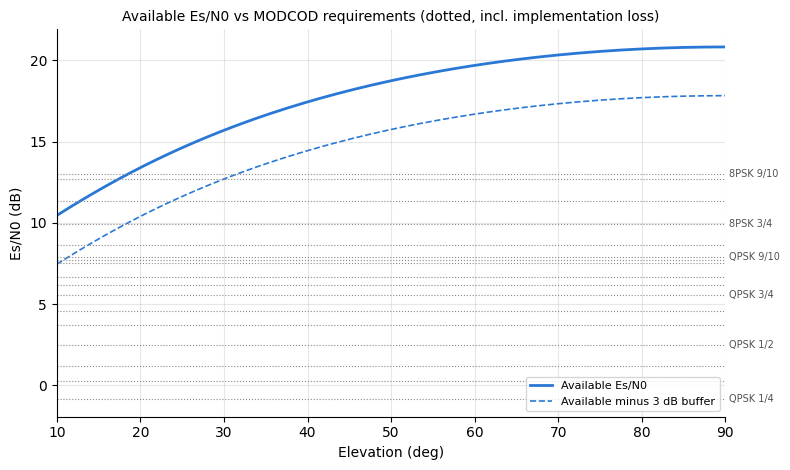

In [9]:
# ===================== MODCOD table and VCM functions =====================
# SOURCE CHECK (vs trade study v1; compared numerically):
#   DVBS2_TABLE_ALL   -> CHANGED: QPSK + 8PSK rows only. GMSK, LoRa and APSK modes dropped.
#   pilot_factor      -> SAME as source
#   MODCODS           -> NEW: one table, one row per MODCOD sorted slowest to fastest: ideal Es/N0 threshold,
#                        implementation loss (8PSK adds WAVEFORM["impl_extra_dB"]), req_total_dB = the two added
#                        (what the link must actually deliver), and info rate at the fixed symbol rate after pilots.
#                        Row 0 is "off" (rate 0, never decodes), so a MODCOD index of 0 means the transmitter is off.
#   vcm_select        -> NEW: fixed symbol rate, fastest MODCOD with >= buffer predicted margin. For QPSK only it
#                        matches the source "best QPSK at fixed Rs" rule exactly. The source solve_mode /
#                        best_rate_bps (which vary the symbol rate) are deliberately not used.
#   vcm_schedule      -> NEW: builds the VCM table the satellite carries: one MODCOD per elevation step, chosen
#                        from the nominal budget before the pass.
#   modcod_at_elevation   -> NEW: during a pass, finds the table row for the current elevation (the row at or below it).
#   pass_MB           -> NEW: MB from one pass (its elevation samples) flown with a given schedule, assuming every
#                        frame decodes.
#   average_pass_MB   -> NEW: builds the schedule once, then averages pass_MB over every simulated pass (Section 3.2).

# ---- DVB-S2 MODCODs: ETSI EN 302 307-1 Table 13 (ideal Es/N0 at quasi-error-free, normal frames) ----
# name: (required Es/N0 [dB], spectral efficiency eta [info bits per symbol, no pilots], bits per symbol m)
DVBS2_TABLE_ALL = {
    "QPSK 1/4": (-2.35, 0.490, 2), "QPSK 1/3": (-1.24, 0.656, 2), "QPSK 2/5": (-0.30, 0.789, 2),
    "QPSK 1/2": ( 1.00, 0.988, 2), "QPSK 3/5": ( 2.23, 1.188, 2), "QPSK 2/3": ( 3.10, 1.322, 2),
    "QPSK 3/4": ( 4.03, 1.487, 2), "QPSK 4/5": ( 4.68, 1.587, 2), "QPSK 5/6": ( 5.18, 1.655, 2),
    "QPSK 8/9": ( 6.20, 1.766, 2), "QPSK 9/10": (6.42, 1.789, 2),
    "8PSK 3/5": ( 5.50, 1.779, 3), "8PSK 2/3": ( 6.62, 1.981, 3), "8PSK 3/4": ( 7.91, 2.228, 3),
    "8PSK 5/6": ( 9.35, 2.479, 3), "8PSK 8/9": (10.69, 2.646, 3), "8PSK 9/10": (10.98, 2.679, 3),
}
MODULATIONS = ("QPSK", "8PSK") if WAVEFORM["include_8psk"] else ("QPSK",)
DVBS2_TABLE = {k: v for k, v in DVBS2_TABLE_ALL.items() if k.split()[0] in MODULATIONS}

def pilot_factor(m, normal=True):
    '''Fraction of transmitted symbols carrying data with pilots on: 90-symbol header, 90-symbol slots,
    36 pilot symbols every 16 slots. m = bits per symbol: QPSK (2) -> 0.9762, 8PSK (3) -> 0.9765.'''
    slots = (64800 if normal else 16200)/m/90
    nopilot = 90*(1 + slots)
    return nopilot/(nopilot + 36*np.floor((slots - 1)/16))

# One row per MODCOD, slowest -> fastest. Row 0 is "off": rate 0 and no threshold (NaN), so it never "fits" or
# decodes, and index 0 means the transmitter is off.
MODCODS = pd.DataFrame([dict(modcod=n, req_esn0_dB=req,
                             impl_dB=WAVEFORM["impl_loss_dB"] + WAVEFORM["impl_extra_dB"].get(n.split()[0], 0.0),
                             rate_bps=WAVEFORM["Rs_sps"]*eta*(pilot_factor(m) if WAVEFORM["pilots"] else 1.0))
                        for n, (req, eta, m) in DVBS2_TABLE.items()]).sort_values("rate_bps")
MODCODS = pd.concat([pd.DataFrame([dict(modcod="off", req_esn0_dB=np.nan, impl_dB=np.nan, rate_bps=0.0)]), MODCODS],
                    ignore_index=True)
MODCODS["req_total_dB"] = MODCODS["req_esn0_dB"] + MODCODS["impl_dB"]   # what the link must actually supply
REQ_TOTAL_DB = MODCODS["req_total_dB"].to_numpy()                       # numpy copies for fast indexing
RATE_BPS     = MODCODS["rate_bps"].to_numpy()

def vcm_select(esn0_avail_dB, buffer_dB):
    '''VCM rule: row of the FASTEST MODCOD whose predicted margin (available Es/N0 - req_total_dB) is at
    least buffer_dB; 0 ("off") if none fits.'''
    ok = (np.asarray(esn0_avail_dB)[..., None] - REQ_TOTAL_DB) >= buffer_dB   # available MODCOD selection, excluding the "off" MODCOD
    return np.where(ok, RATE_BPS, -1.0).argmax(axis=-1)                       # choosing maximum data rate MODCOD, or "off" if no MODCOD availables

def vcm_schedule(buffer_dB, design=None, alt_km=None):
    '''The VCM table the satellite would carry: one MODCOD per elevation step from the mask to 90 deg.
    Built from the NOMINAL link budget (it is decided before the pass). Returns (grid, sched_modcod): elevations [deg] and the MODCOD row chosen for each.'''
    grid = np.arange(MISSION["min_el_deg"], 90 + 1e-9, WAVEFORM["sched_step_deg"])
    esn0 = link_budget(grid, design=design, alt_km=alt_km)["= Available Es/N0"]
    return grid, vcm_select(esn0, buffer_dB)

def modcod_at_elevation(grid, sched_modcod, el_deg):
    '''MODCOD index in use at elevation(s) el_deg.'''
    k = np.clip(np.floor((np.asarray(el_deg) - grid[0])/WAVEFORM["sched_step_deg"]).astype(int), 0, len(grid) - 1)
    return sched_modcod[k], k

def pass_MB(el_deg, schedule):
    '''MB delivered by one pass with elevation samples el_deg (one every DT_S seconds), flown with
    schedule = vcm_schedule(...), if every frame decodes (the nominal case; Section 7 adds uncertainty).'''
    idx, _ = modcod_at_elevation(*schedule, el_deg)
    return RATE_BPS[idx].sum()*DT_S*WAVEFORM["payload_frac"]/8e6

def average_pass_MB(buffer_dB, design=None, alt_km=None):
    '''Mean MB per pass over every simulated pass (PASSES, Section 3.2).'''
    schedule = vcm_schedule(buffer_dB, design=design, alt_km=alt_km)    # same table for every pass
    return pass_MB(np.concatenate(PASSES), schedule)/len(PASSES)

print(f"Modulations: {', '.join(MODULATIONS)}; symbol rate {WAVEFORM['Rs_sps']/1e6:g} Msym/s, occupied bandwidth "
      f"~{WAVEFORM['Rs_sps']*(1 + WAVEFORM['rolloff'])/1e6:.1f} MHz")
display(MODCODS.iloc[1:].set_index("modcod").assign(rate_Mbps=lambda t: t.rate_bps/1e6)
               .drop(columns="rate_bps").round(2))

# ---- Chart: available Es/N0 vs elevation, with each MODCOD's requirement ----
e_fine = np.linspace(MISSION["min_el_deg"], 90, 161)
avail = link_budget(e_fine)["= Available Es/N0"]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(e_fine, avail, color=SERIES[0], label="Available Es/N0")
ax.plot(e_fine, avail - WAVEFORM["vcm_buffer_dB"], color=SERIES[0], ls="--", lw=1.2,
        label=f"Available minus {WAVEFORM['vcm_buffer_dB']:g} dB buffer")
LABELLED = ("QPSK 1/4", "QPSK 1/2", "QPSK 3/4", "QPSK 9/10", "8PSK 3/4", "8PSK 9/10")      # label a few lines only, so labels don't collide
for name, req in zip(MODCODS.modcod[1:], MODCODS.req_total_dB[1:]):
    ax.axhline(req, color=REF_GREY, lw=0.8, ls=":")
    if name in LABELLED:
        ax.text(90.5, req, name, va="center", fontsize=7, color="#52514e")
ax.set_xlim(MISSION["min_el_deg"], 90)
ax.set_xlabel("Elevation (deg)"); ax.set_ylabel("Es/N0 (dB)")
ax.set_title("Available Es/N0 vs MODCOD requirements (dotted, incl. implementation loss)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

VCM schedule (3 dB buffer, 8 Msym/s): each MODCOD is used from this elevation upward


,modcod,info_rate_Mbps,predicted_margin_dB
elev_deg,,,
10.0,QPSK 5/6,12.92,3.78
11.0,8PSK 3/5,13.91,3.28
12.0,QPSK 9/10,13.97,3.18
14.0,8PSK 2/3,15.49,3.09
19.0,8PSK 3/4,17.42,3.23
24.0,8PSK 5/6,19.38,3.05
30.0,8PSK 8/9,20.69,3.01
32.0,8PSK 9/10,20.95,3.11


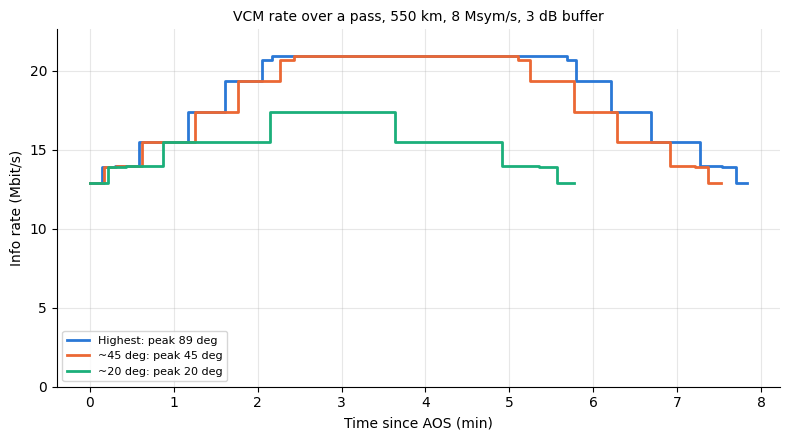

Highest pass  (peak 88.9 deg): 1070.2 MB in 7.8 min


~45 deg pass  (peak 45.2 deg): 1008.4 MB in 7.5 min
~20 deg pass  (peak 20.0 deg):  659.5 MB in 5.8 min
Average pass:   774.8 MB  ->  2.51 GB/day at 3.23 passes/day

PFD: worst case -3.4 dB vs the Table 21-4 limit (under); largest compliant PA output 10.86 W [benchmark only on the current licence route]


In [10]:
VCM_BUFFER = WAVEFORM["vcm_buffer_dB"]
grid, sched_modcod = vcm_schedule(VCM_BUFFER)
esn0_grid = link_budget(grid)["= Available Es/N0"]

sched = pd.DataFrame({"elev_deg": grid,
                      "modcod": MODCODS.modcod.to_numpy()[sched_modcod],
                      "info_rate_Mbps": RATE_BPS[sched_modcod]/1e6,
                      "predicted_margin_dB": esn0_grid - REQ_TOTAL_DB[sched_modcod]})   # NaN where off
steps = sched[sched["modcod"] != sched["modcod"].shift()]          # rows where the MODCOD changes
print(f"VCM schedule ({VCM_BUFFER:g} dB buffer, {WAVEFORM['Rs_sps']/1e6:g} Msym/s): each MODCOD is used from this elevation upward")
display(steps.set_index("elev_deg").round(2))

# ---- Chart: info rate over three simulated passes (highest, ~45 deg and ~20 deg peak) ----
examples = {"Highest":  int(PASS_PEAKS.argmax()),
            "~45 deg":  int(np.abs(PASS_PEAKS - 45).argmin()),
            "~20 deg":  int(np.abs(PASS_PEAKS - 20).argmin())}
fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (name, i) in enumerate(examples.items()):
    el = PASSES[i]
    idx, _ = modcod_at_elevation(grid, sched_modcod, el)
    ax.step(np.arange(len(el))*DT_S/60, RATE_BPS[idx]/1e6, where="post", color=SERIES[k],
            label=f"{name}: peak {PASS_PEAKS[i]:.0f} deg")
ax.set_ylim(0, RATE_BPS.max()/1e6*1.08)
ax.set_xlabel("Time since AOS (min)"); ax.set_ylabel("Info rate (Mbit/s)")
ax.set_title(f"VCM rate over a pass, {MISSION['alt_km']:g} km, {WAVEFORM['Rs_sps']/1e6:g} Msym/s, {VCM_BUFFER:g} dB buffer", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- Data per pass (nominal: every frame decodes) ----
avg_MB = average_pass_MB(VCM_BUFFER)
for name, i in examples.items():
    print(f"{name + ' pass':13s} (peak {PASS_PEAKS[i]:4.1f} deg): {pass_MB(PASSES[i], (grid, sched_modcod)):6.1f} MB "
          f"in {len(PASSES[i])*DT_S/60:.1f} min")
print(f"Average pass:  {avg_MB:6.1f} MB  ->  {avg_MB*PASSES_PER_DAY/1e3:.2f} GB/day at {PASSES_PER_DAY:.2f} passes/day")

# ---- PFD check ----
excess = pfd_worst_excess_dB()
print(f"\nPFD: worst case {excess:+.1f} dB vs the Table 21-4 limit "
      f"({'OVER' if excess > 0 else 'under'}); largest compliant PA output {pfd_max_power_W():.2f} W "
      f"[{'binding' if CONSTRAINTS['pfd_binding'] else 'benchmark only'} on the current licence route]")

## 6. PA power study (D1, deterministic)
The antenna (Taoglas patch) and pointing (steered at the GS) are fixed, so the remaining hardware decision is the PA output power. Each value in `CANDIDATES["pa_W"]` goes through the full chain (link budget → its own VCM schedule → every simulated pass) with everything else at baseline. Numbers are **average-pass MB, every frame decoding**, at the Section 2 buffer.

Each doubling of power adds 3 dB at every elevation, so the schedule can use faster MODCODs throughout; the gain flattens once most of the pass is already at the fastest MODCOD. Grey line: the 3 W structures limit. Hollow markers: powers over the PFD limit.

Average MB per pass and GB per day at 3.23 passes/day, 3 dB buffer, 8 Msym/s


,avg_MB,GB_per_day,pfd_excess_dB,over_struct
pa_W,,,,
1,392.63,1.27,-10.36,False
2,566.63,1.83,-7.35,False
3,668.04,2.16,-5.59,False
4,728.08,2.35,-4.34,True
5,774.81,2.51,-3.37,True
6,809.56,2.62,-2.58,True
7,839.34,2.71,-1.91,True
8,862.86,2.79,-1.33,True
9,889.44,2.88,-0.81,True


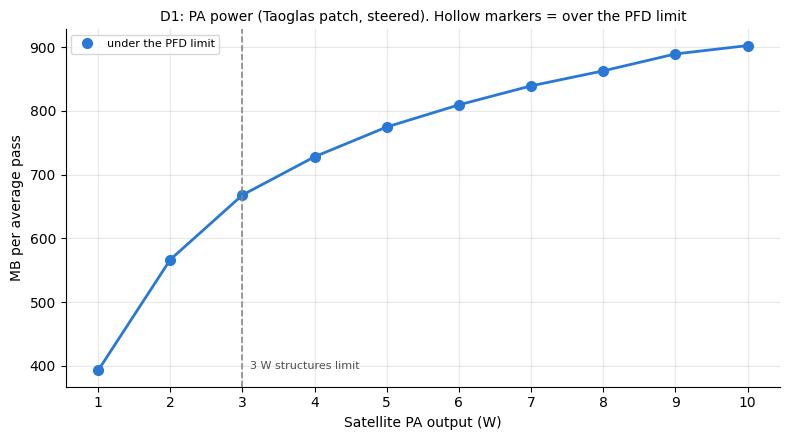

In [11]:
# ---- D1: PA power sweep (Taoglas patch, steered), with the 3 W line and PFD flags ----
rows = []
for pw in CANDIDATES["pa_W"]:
    dsg = dict(pa_out_W=pw)
    mb = average_pass_MB(VCM_BUFFER, design=dsg)
    rows.append(dict(pa_W=pw, avg_MB=mb, GB_per_day=mb*PASSES_PER_DAY/1e3,
                     pfd_excess_dB=pfd_worst_excess_dB(dsg), over_struct=pw > CONSTRAINTS["pa_struct_W"]))
d1 = pd.DataFrame(rows).set_index("pa_W")
print(f"Average MB per pass and GB per day at {PASSES_PER_DAY:.2f} passes/day, {VCM_BUFFER:g} dB buffer, "
      f"{WAVEFORM['Rs_sps']/1e6:g} Msym/s")
display(d1.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(d1.index, d1.avg_MB, color=SERIES[0])
ok, bad = d1[d1.pfd_excess_dB <= 0], d1[d1.pfd_excess_dB > 0]
ax.plot(ok.index, ok.avg_MB, "o", ms=7, color=SERIES[0], label="under the PFD limit")
if len(bad):
    ax.plot(bad.index, bad.avg_MB, "o", ms=7, mfc="white", mec=SERIES[0], mew=1.5, label="over the PFD limit")
ax.axvline(CONSTRAINTS["pa_struct_W"], color=REF_GREY, ls="--", lw=1.2)
ax.text(CONSTRAINTS["pa_struct_W"] + 0.1, ax.get_ylim()[0] + 0.05*np.ptp(ax.get_ylim()), "3 W structures limit",
        fontsize=8, color="#52514e")
ax.set_xticks(CANDIDATES["pa_W"])
ax.set_xlabel("Satellite PA output (W)"); ax.set_ylabel("MB per average pass")
ax.set_title("D1: PA power (Taoglas patch, steered). Hollow markers = over the PFD limit", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Monte Carlo: how much really gets through
Section 5 assumed every frame decodes. In reality the parts differ from their datasheets and the pointing wobbles. The schedule is still chosen from the **nominal** budget (it is uploaded before the pass), so a step fails when reality falls more than one buffer below the prediction.

**Spreads are "before calibration"** (launch and commissioning). The `MC` comments in Section 2 mark which terms calibration on the first passes would remove (fixed hardware offsets) and which stay (things that vary from pass to pass).

**Two kinds of randomness**, kept separate on purpose:
- **Per-pass biases** (drawn once per simulated pass): satellite antenna gain, PA power, satellite cable loss, dish gain, system temperature (RFI that only ever adds noise, LNA noise figure), polarization mismatch, implementation loss. A part that is 1 dB low is 1 dB low for the whole pass, so failures come in stretches, not as random single frames.
- **Per-second jitter**: satellite pointing error (Rayleigh, with `SAT_S["pointing_err_deg"]` as its 95th percentile) and dish tracking loss.

Each simulated pass is a real pass picked at random from the Section 3.2 orbit simulation, so the mix of high and low passes matches a 98° orbit over Stanford.

For every time sample: actual margin = predicted margin of the scheduled MODCOD + Δ, where Δ (dB) is the sum of all the deviations from nominal. The frame decodes if the actual margin ≥ 0.

**Outputs**
1. Distribution of delivered MB per pass at the Section 2 buffer.
2. Chance each schedule step decodes (vs elevation).
3. Tornado: how much delivered data each uncertainty costs (delivered MB with that one uncertainty removed, minus delivered MB with all of them). "Removed" means that term is held at its nominal value. A **negative** bar means the nominal value is pessimistic: the satellite pointing error is held at 5° (its 95th percentile) in the schedule, so the typical real error is smaller and removing the randomness makes things slightly worse.

Delivered data counts only frames that decode first time. Failed frames used airtime and are resent later, so they do not count towards this pass.

In [12]:
def draw_monte_carlo(n_passes=None, seed=RNG_SEED, design=None):
    '''Simulate n_passes passes. Returns one flat table of time samples (all passes concatenated) with:
    pass id, elevation, nominal available Es/N0, and each deviation component in dB (positive = better
    than nominal). Nothing here depends on the buffer, so Section 8 can reuse the same draws.'''
    n_passes = MC["n_passes"] if n_passes is None else n_passes
    d   = {**DECISIONS, **(design or {})}
    rng = np.random.default_rng(seed)

    # ---- per-pass biases [dB, positive = better link] ----
    bias = dict(
        sat_ant  = rng.normal(0, MC["sat_ant_std_dB"], n_passes),
        pa       = rng.normal(0, MC["pa_std_dB"], n_passes),
        sat_loss = -rng.normal(0, MC["sat_loss_std_dB"], n_passes),
        dish     = rng.normal(0, MC["dish_gain_std_dB"], n_passes),
        pol      = -(np.clip(rng.normal(GS_S["pol_loss_dB"], MC["pol_std_dB"], n_passes), 0, None) - GS_S["pol_loss_dB"]),
        impl     = -(np.clip(rng.normal(WAVEFORM["impl_loss_dB"], MC["impl_std_dB"], n_passes), 0, None) - WAVEFORM["impl_loss_dB"]),
    )
    T_ant = GS_S["T_ant_K"] + rng.exponential(MC["T_rfi_mean_K"], n_passes)          # RFI only adds noise
    nf    = np.clip(GS_S["lna_nf_dB"] + rng.normal(0, MC["lna_nf_std_dB"], n_passes), 0.1, None)
    tsys  = tsys_at_lna_input(T_ant, GS_S["feed_loss_dB"], nf, GS_S["lna_gain_dB"], GS_S["post_loss_dB"], GS_S["rx_nf_dB"])
    bias["tsys"] = -10*np.log10(tsys/TSYS_K)

    # ---- pass geometry: each simulated pass is a real pass drawn at random from PASSES (Section 3.2) ----
    pick = rng.integers(len(PASSES), size=n_passes)
    # Rayleigh scale so that P(error < pointing_err_deg) = 95%
    ray_sigma = SAT_S["pointing_err_deg"]/np.sqrt(-2*np.log(0.05))

    parts = []
    for i, j in enumerate(pick):
        el = PASSES[j]; n = len(el)
        nominal = link_budget(el, design=d)            # nominal budget uses the 5 deg error, like the schedule
        err = rng.rayleigh(ray_sigma, n)                 # actual satellite pointing error each second
        sat_pt = nominal["- Sat pointing loss"] - sat_point_loss_db(err)
        dish_pt = GS_S["point_loss_dB"] - np.clip(GS_S["point_loss_dB"] + rng.normal(0, MC["dish_point_std_dB"], n), 0, None)
        row = dict(pass_id=np.full(n, i), el_deg=el, esn0_nom=nominal["= Available Es/N0"],
                   sat_point=sat_pt, dish_point=dish_pt)
        for k, v in bias.items():
            row[k] = np.full(n, v[i])
        parts.append(pd.DataFrame(row))
    samples = pd.concat(parts, ignore_index=True)
    samples.attrs.update(n_passes=n_passes, components=list(bias) + ["sat_point", "dish_point"])
    return samples

def evaluate_buffer(samples, buffer_dB, drop=(), design=None):
    '''Apply one buffer to the Monte Carlo samples.
    drop: uncertainty components to switch off (for the tornado). design: overrides DECISIONS for the schedule.
    Returns dict: mean delivered and transmitted MB per pass, overall reliability (delivered / transmitted
    bits), worst-step reliability (lowest decode rate of any schedule step), per-step decode table,
    and delivered MB per pass.'''
    grid, sched_modcod = vcm_schedule(buffer_dB, design=design)
    idx, step = modcod_at_elevation(grid, sched_modcod, samples["el_deg"].to_numpy())
    on = idx > 0                                    # row 0 = transmitter off
    rate = RATE_BPS[idx]                            # 0 when off
    delta = sum(samples[c].to_numpy() for c in samples.attrs["components"] if c not in drop)
    decoded = (samples["esn0_nom"].to_numpy() - REQ_TOTAL_DB[idx] + delta) >= 0   # NaN ("off") -> False

    scale = DT_S*WAVEFORM["payload_frac"]/8e6       # bits/s * s -> MB
    n_passes = samples.attrs["n_passes"]
    sent_MB = rate.sum()*scale/n_passes
    good_MB = (rate*decoded).sum()*scale/n_passes
    per_pass = pd.Series(rate*decoded*scale).groupby(samples["pass_id"].to_numpy()).sum()

    st = pd.DataFrame(dict(step=step[on], el=grid[step[on]], decoded=decoded[on]))
    per_step = st.groupby("el").decoded.agg(["mean", "size"])
    per_step = per_step[per_step["size"] >= 30]                 # ignore steps with too few samples to trust
    return dict(good_MB=good_MB, sent_MB=sent_MB,
                overall_rel=good_MB/sent_MB if sent_MB > 0 else np.nan,
                worst_rel=per_step["mean"].min() if len(per_step) else np.nan,
                per_step=per_step, per_pass=per_pass)

SAMPLES = draw_monte_carlo()
print(f"Monte Carlo: {SAMPLES.attrs['n_passes']} passes, {len(SAMPLES):,} one-second samples")

Monte Carlo: 600 passes, 219,717 one-second samples


Buffer 3 dB: mean delivered 706.1 MB/pass of 765.1 MB sent (nominal average pass: 774.8 MB)
Overall reliability 92.3%  ->  7.7% of transmitted data needs a resend
Worst schedule step decodes 86.2% of the time
Delivered per pass: median 800.7 MB, 10th percentile 225.3 MB, 90th percentile 1056.0 MB


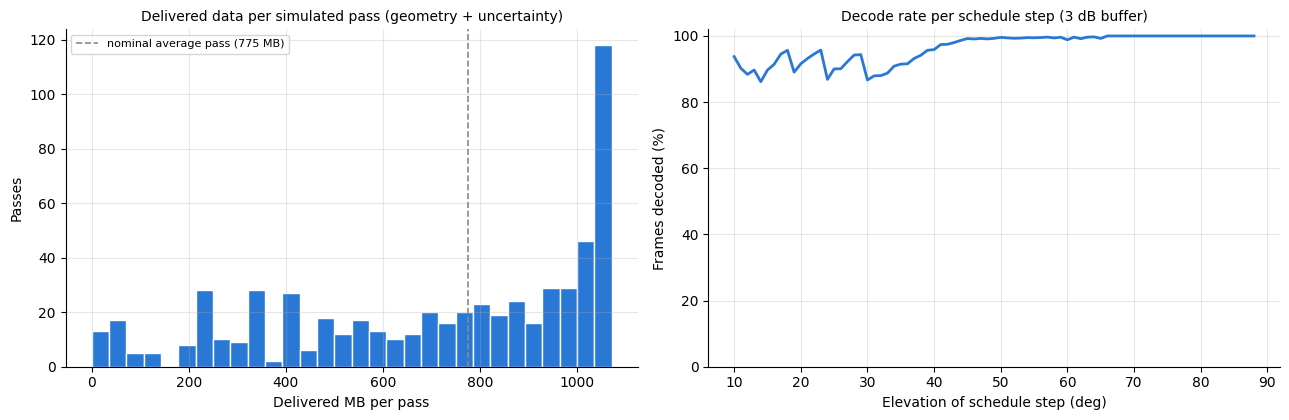

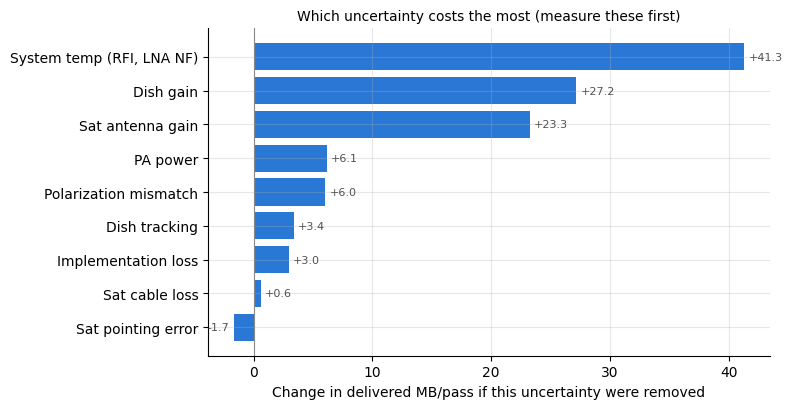

In [13]:
res = evaluate_buffer(SAMPLES, VCM_BUFFER)
print(f"Buffer {VCM_BUFFER:g} dB: mean delivered {res['good_MB']:.1f} MB/pass of {res['sent_MB']:.1f} MB sent "
      f"(nominal average pass: {avg_MB:.1f} MB)")
print(f"Overall reliability {res['overall_rel']:.1%}  ->  {1 - res['overall_rel']:.1%} of transmitted data needs a resend")
print(f"Worst schedule step decodes {res['worst_rel']:.1%} of the time")
pp = res["per_pass"]
print(f"Delivered per pass: median {pp.median():.1f} MB, 10th percentile {pp.quantile(0.1):.1f} MB, "
      f"90th percentile {pp.quantile(0.9):.1f} MB")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].hist(pp, bins=30, color=SERIES[0], edgecolor="white")
axes[0].axvline(avg_MB, color=REF_GREY, ls="--", lw=1.2, label=f"nominal average pass ({avg_MB:.0f} MB)")
axes[0].set_xlabel("Delivered MB per pass"); axes[0].set_ylabel("Passes")
axes[0].set_title("Delivered data per simulated pass (geometry + uncertainty)", fontsize=10)
axes[0].legend(fontsize=8)

ps = res["per_step"]
axes[1].plot(ps.index, 100*ps["mean"], color=SERIES[0])
axes[1].set_ylim(0, 102)
axes[1].set_xlabel("Elevation of schedule step (deg)"); axes[1].set_ylabel("Frames decoded (%)")
axes[1].set_title(f"Decode rate per schedule step ({VCM_BUFFER:g} dB buffer)", fontsize=10)
plt.tight_layout(); plt.show()

# ---- Tornado: delivered MB gained if each uncertainty were removed ----
labels = dict(sat_ant="Sat antenna gain", pa="PA power", sat_loss="Sat cable loss", dish="Dish gain",
              pol="Polarization mismatch", impl="Implementation loss", tsys="System temp (RFI, LNA NF)",
              sat_point="Sat pointing error", dish_point="Dish tracking")
gain = pd.Series({labels[c]: evaluate_buffer(SAMPLES, VCM_BUFFER, drop=(c,))["good_MB"] - res["good_MB"]
                  for c in SAMPLES.attrs["components"]}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(gain.index, gain.values, color=SERIES[0])
ax.bar_label(bars, fmt="%+.1f", fontsize=8, color="#52514e", padding=3)
ax.axvline(0, color=REF_GREY, lw=0.8)
ax.set_xlabel("Change in delivered MB/pass if this uncertainty were removed")
ax.set_title("Which uncertainty costs the most (measure these first)", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Store-and-forward downlink: choosing the VCM buffer (D2)
In store-and-forward, data is recorded on board and sent down during passes. A frame that fails is resent on a later pass, so what matters is the **total data delivered**, not every frame arriving.

The buffer trades speed for reliability. A small buffer picks fast MODCODs that often fail; a large buffer picks slow MODCODs that almost always decode. We sweep it, reusing the **same** Monte Carlo draws for every value (so the curves are smooth and comparable), and look at:

- **Delivered MB per pass** (first-time decodes only). This is what we maximise.
- **Overall reliability** = delivered ÷ transmitted data. `1 − overall` is the share of transmitted data that must be resent on a later pass.
- **Worst-step reliability** = the decode rate of the weakest schedule step. Because errors are mostly per-pass biases, a low worst step means some passes systematically fail at those elevations, which costs UHF uplink capacity for resend requests, delay and onboard backlog. We require it to stay above `BUFFER_SWEEP["worst_step_floor"]`.

**Recommendation rule:** the buffer that maximises delivered MB per pass among buffers whose worst step meets the floor. Copy it into `WAVEFORM["vcm_buffer_dB"]` and re-run.

,good_MB,sent_MB,overall_rel_pct,worst_rel_pct
buffer_dB,,,,
0.0,562.2,890.8,63.1,37.5
0.5,599.8,875.9,68.5,48.2
1.0,647.1,850.0,76.1,58.9
1.5,668.3,837.3,79.8,64.8
2.0,689.6,812.4,84.9,73.8
2.5,700.3,787.0,89.0,80.3
3.0,706.1,765.1,92.3,86.2
3.5,703.7,742.1,94.8,90.1
4.0,695.0,719.1,96.6,93.7


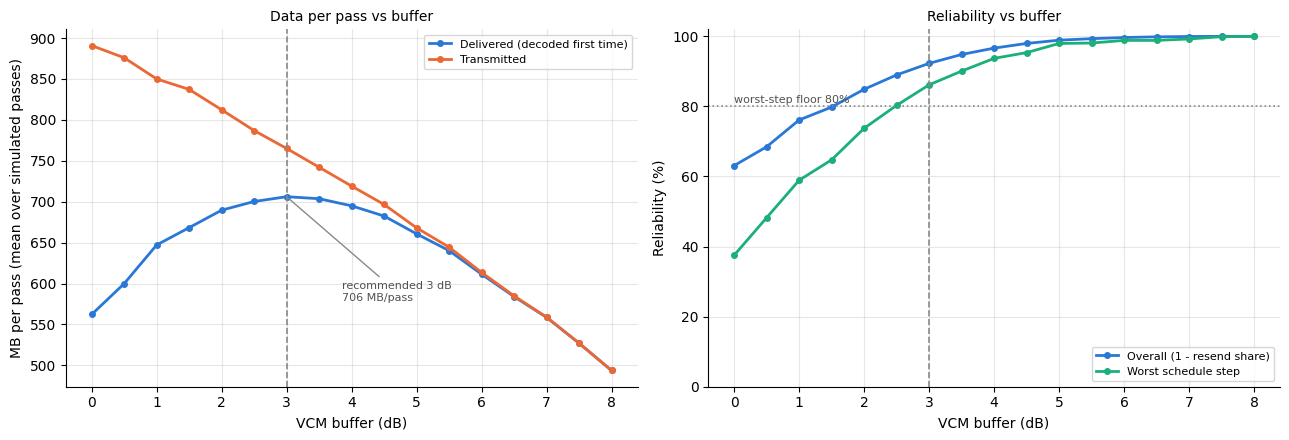

Unconstrained maximum: 706.1 MB/pass at 3 dB (worst step 86%)
Recommended buffer (worst step >= 80%): 3 dB -> 706.1 MB/pass, overall reliability 92.3% (resend 7.7%), worst step 86.2%
-> set WAVEFORM['vcm_buffer_dB'] = 3 in Section 2 and re-run


In [14]:
# ---- The sweep: try every candidate VCM buffer against the SAME 600 simulated passes ----
# What is swept: only the buffer (0, 0.5, ..., 8 dB from BUFFER_SWEEP["buffers_dB"]). For each value,
# evaluate_buffer builds a new VCM schedule with that buffer (bigger buffer -> slower, safer MODCODs),
# flies it through the Section 7 samples, and counts what decodes.
sweep = pd.DataFrame([dict(buffer_dB=bf, **{k: v for k, v in evaluate_buffer(SAMPLES, bf).items()
                                            if k in ("good_MB", "sent_MB", "overall_rel", "worst_rel")})
                      for bf in BUFFER_SWEEP["buffers_dB"]])

# ---- Pick the recommended buffer ----
# Rule: among buffers whose weakest step still decodes on >= floor (80%) of passes, take the one that
# delivers the most data.
floor = BUFFER_SWEEP["worst_step_floor"]
feasible = sweep[sweep.worst_rel >= floor]                       # buffers that pass the reliability floor
best_any = sweep.loc[sweep.good_MB.idxmax()]                     # most data ignoring the floor (for comparison)
BUFFER_REC = float(feasible.loc[feasible.good_MB.idxmax(), "buffer_dB"]) if len(feasible) else float("nan")
rec = sweep[sweep.buffer_dB == BUFFER_REC].iloc[0] if len(feasible) else None   # the full row for the pick

display(sweep.assign(overall_rel_pct=100*sweep.overall_rel, worst_rel_pct=100*sweep.worst_rel)
             [["buffer_dB", "good_MB", "sent_MB", "overall_rel_pct", "worst_rel_pct"]].round(1).set_index("buffer_dB"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
# Left: delivered (and transmitted) data per pass vs buffer
ax1.plot(sweep.buffer_dB, sweep.good_MB, color=SERIES[0], marker="o", ms=4, label="Delivered (decoded first time)")
ax1.plot(sweep.buffer_dB, sweep.sent_MB, color=SERIES[1], marker="o", ms=4, label="Transmitted")
if rec is not None:
    ax1.axvline(BUFFER_REC, color=REF_GREY, ls="--", lw=1.2)
    ax1.annotate(f"recommended {BUFFER_REC:g} dB\n{rec.good_MB:.0f} MB/pass", (BUFFER_REC, rec.good_MB),
                 xytext=(40, -75), textcoords="offset points", fontsize=8, color="#52514e",
                 arrowprops=dict(arrowstyle="-", color=REF_GREY))
ax1.set_xlabel("VCM buffer (dB)"); ax1.set_ylabel("MB per pass (mean over simulated passes)")
ax1.set_title("Data per pass vs buffer", fontsize=10); ax1.legend(fontsize=8)
# Right: overall and worst-step reliability vs buffer
ax2.plot(sweep.buffer_dB, 100*sweep.overall_rel, color=SERIES[0], marker="o", ms=4, label="Overall (1 - resend share)")
ax2.plot(sweep.buffer_dB, 100*sweep.worst_rel, color=SERIES[2], marker="o", ms=4, label="Worst schedule step")
ax2.axhline(100*floor, color=REF_GREY, ls=":", lw=1.2)
ax2.text(sweep.buffer_dB.min(), 100*floor + 1, f"worst-step floor {floor:.0%}", fontsize=8, color="#52514e")
if rec is not None:
    ax2.axvline(BUFFER_REC, color=REF_GREY, ls="--", lw=1.2)
ax2.set_ylim(0, 102)
ax2.set_xlabel("VCM buffer (dB)"); ax2.set_ylabel("Reliability (%)")
ax2.set_title("Reliability vs buffer", fontsize=10); ax2.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

print(f"Unconstrained maximum: {best_any.good_MB:.1f} MB/pass at {best_any.buffer_dB:g} dB "
      f"(worst step {best_any.worst_rel:.0%})")
if rec is not None:
    print(f"Recommended buffer (worst step >= {floor:.0%}): {BUFFER_REC:g} dB -> {rec.good_MB:.1f} MB/pass, "
          f"overall reliability {rec.overall_rel:.1%} (resend {1 - rec.overall_rel:.1%}), worst step {rec.worst_rel:.1%}")
    print(f"-> set WAVEFORM['vcm_buffer_dB'] = {BUFFER_REC:g} in Section 2 and re-run")
else:
    print(f"No buffer in the sweep meets the {floor:.0%} worst-step floor: widen the sweep or revisit the floor")

## 9. Live-stream downlink: reliability vs data rate (D3)
Section 8 assumes failed frames are resent later. A **live stream** can't wait for that: a frame that fails is a gap in the stream. So instead of maximising total data, pick the reliability the stream needs and see what rate is left.

Same buffers, same Monte Carlo passes as Section 8, judged differently:
- **Delivered (%)** = delivered ÷ transmitted: the share of the stream that arrives. 100% minus this is the gap rate.
- **Worst step delivered (%)**: the same at the weakest elevation step, where gaps cluster.
- **Average stream rate (Mbit/s)**: payload delivered ÷ time above the mask, averaged over passes. VCM still steps the MODCOD up with elevation, so the stream is slowest at the start and end of each pass.
- **Rate at the mask (Mbit/s)**: the scheduled rate at the mask elevation, the slowest point of every pass.

The reliability chart shows only 95–100%. Dotted lines mark the example targets in `BUFFER_SWEEP["stream_targets"]`. On the rate chart, dashed lines mark typical video bitrates (`VIDEO_RATES_MBPS`). A stream at a fixed quality has to fit the **rate at the mask**; one that follows the average needs an encoder that lowers quality at the start and end of each pass. For each target the cell prints the smallest buffer that meets it (overall, and also at the worst step) and the rate that buffer leaves.

**PA power × reliability table.** The last chart asks the question the other way round: for each PA power and each worst-step target, take the smallest buffer whose weakest step meets the target and report the **rate at the mask** it leaves, the slowest point of every pass and so what a fixed-quality stream has to fit. The colour is the best video quality in `VIDEO_RATES_MBPS` that fits that rate. PA power adds the same dB at every elevation, so each power reuses the Section 7 random draws with the nominal $E_s/N_0$ shifted; only the power changes between columns.

,delivered_pct,worst_step_pct,avg_rate_Mbps,rate_at_mask_Mbps
buffer_dB,,,,
0.0,63.11,37.53,12.28,17.42
0.5,68.48,48.24,13.10,17.42
1.0,76.12,58.93,14.14,15.49
1.5,79.81,64.75,14.60,15.49
2.0,84.89,73.75,15.07,13.97
2.5,88.98,80.30,15.30,13.97
3.0,92.28,86.16,15.43,12.92
3.5,94.82,90.07,15.37,12.92
4.0,96.64,93.71,15.18,12.39


95% delivered (overall             ): buffer 4 dB -> average 15.18 Mbit/s, 12.39 Mbit/s at the mask, worst step 93.7%
95% delivered (overall + worst step): buffer 4.5 dB -> average 14.91 Mbit/s, 11.61 Mbit/s at the mask, worst step 95.4%
99% delivered (overall             ): buffer 5.5 dB -> average 13.99 Mbit/s, 10.32 Mbit/s at the mask, worst step 98.1%
99% delivered (overall + worst step): buffer 7 dB -> average 12.20 Mbit/s, 7.72 Mbit/s at the mask, worst step 99.3%


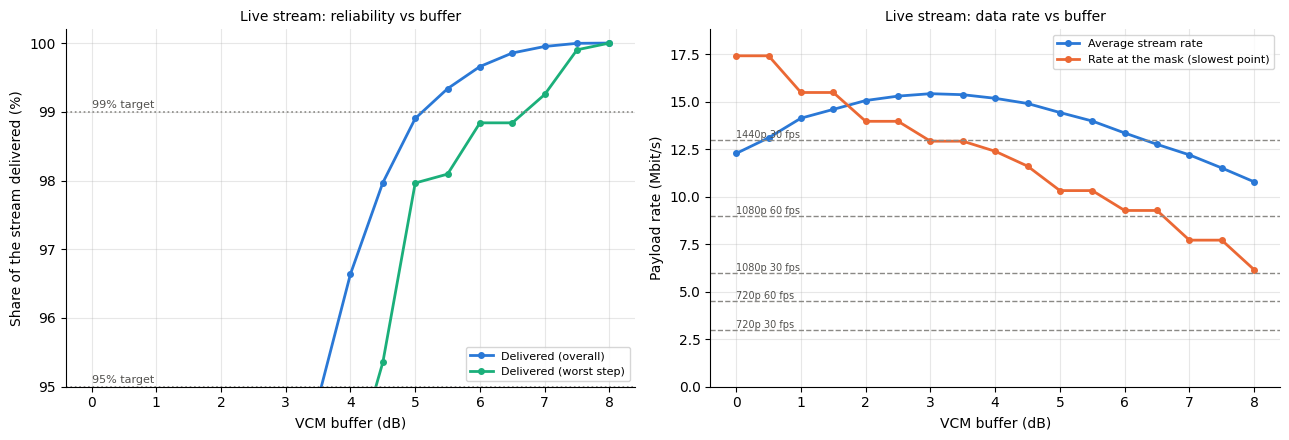

In [15]:
# ---- Live stream: the Section 8 sweep, read as reliability vs rate ----
pass_time_s = len(SAMPLES)*DT_S/SAMPLES.attrs["n_passes"]          # mean time above the mask per pass [s]
stream = sweep[["buffer_dB", "overall_rel", "worst_rel", "good_MB"]].copy()
stream["avg_rate_Mbps"] = stream.good_MB*8/pass_time_s              # delivered payload rate while above the mask
stream["rate_at_mask_Mbps"] = [RATE_BPS[vcm_schedule(bf)[1][0]]/1e6 for bf in stream.buffer_dB]   # slowest point

display(stream.assign(delivered_pct=100*stream.overall_rel, worst_step_pct=100*stream.worst_rel)
              [["buffer_dB", "delivered_pct", "worst_step_pct", "avg_rate_Mbps", "rate_at_mask_Mbps"]]
              .round(2).set_index("buffer_dB"))

# ---- Smallest buffer meeting each target: overall only, and overall + worst step ----
STREAM_PICKS = {}
for target in BUFFER_SWEEP["stream_targets"]:
    for label, ok in (("overall", stream.overall_rel >= target),
                      ("overall + worst step", (stream.overall_rel >= target) & (stream.worst_rel >= target))):
        if ok.any():
            row = stream[ok].iloc[0]                                     # buffers are sorted, so the first is the smallest
            STREAM_PICKS[(target, label)] = row
            print(f"{target:.0%} delivered ({label:20s}): buffer {row.buffer_dB:g} dB -> average {row.avg_rate_Mbps:.2f} Mbit/s, "
                  f"{row.rate_at_mask_Mbps:.2f} Mbit/s at the mask, worst step {row.worst_rel:.1%}")
        else:
            print(f"{target:.0%} delivered ({label}): not reached in the sweep; widen BUFFER_SWEEP['buffers_dB']")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
# Left: how reliability rises with the buffer
ax1.plot(stream.buffer_dB, 100*stream.overall_rel, color=SERIES[0], marker="o", ms=4, label="Delivered (overall)")
ax1.plot(stream.buffer_dB, 100*stream.worst_rel, color=SERIES[2], marker="o", ms=4, label="Delivered (worst step)")
for target in BUFFER_SWEEP["stream_targets"]:
    ax1.axhline(100*target, color=REF_GREY, ls=":", lw=1.2)
    ax1.text(stream.buffer_dB.min(), 100*target + 0.05, f"{target:.0%} target", fontsize=8, color="#52514e")
ax1.set_ylim(95, 100.2)                                             # only the range that matters for a stream
ax1.set_xlabel("VCM buffer (dB)"); ax1.set_ylabel("Share of the stream delivered (%)")
ax1.set_title("Live stream: reliability vs buffer", fontsize=10); ax1.legend(fontsize=8, loc="lower right")
# Right: what that costs in rate
ax2.plot(stream.buffer_dB, stream.avg_rate_Mbps, color=SERIES[0], marker="o", ms=4, label="Average stream rate")
ax2.plot(stream.buffer_dB, stream.rate_at_mask_Mbps, color=SERIES[1], marker="o", ms=4, label="Rate at the mask (slowest point)")
for k, (name, mbps) in enumerate(VIDEO_RATES_MBPS.items()):         # what each rate means as video
    ax2.axhline(mbps, color=REF_GREY, ls="--", lw=1.0)
    ax2.text(stream.buffer_dB.min(), mbps, name, va="bottom", fontsize=7, color="#52514e")
ax2.set_ylim(0, max(stream.avg_rate_Mbps.max(), stream.rate_at_mask_Mbps.max(), max(VIDEO_RATES_MBPS.values()))*1.08)
ax2.set_xlabel("VCM buffer (dB)"); ax2.set_ylabel("Payload rate (Mbit/s)")
ax2.set_title("Live stream: data rate vs buffer", fontsize=10); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

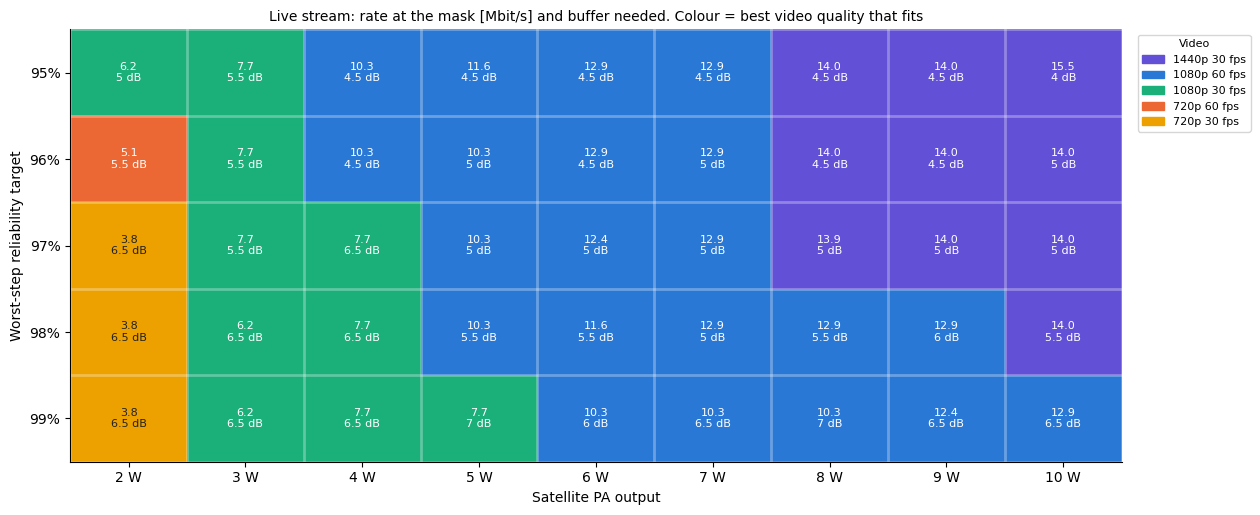

In [16]:
# ---- Rate at the mask by PA power (columns) and worst-step reliability target (rows) ----
# The rate at the mask is the slowest point of every pass, so it is what a fixed-quality stream has to fit.
def samples_at_power(pw):
    '''The Section 7 samples at PA power pw: nominal Es/N0 shifted by the power change in dB, random deviations unchanged.'''
    s = SAMPLES.copy()
    s["esn0_nom"] = s["esn0_nom"] + 10*np.log10(pw/DECISIONS["pa_out_W"])
    s.attrs = dict(SAMPLES.attrs)
    return s

targets, powers = BUFFER_SWEEP["stream_table_targets"], BUFFER_SWEEP["stream_table_pa_W"]
rows = [f"{t:.0%}" for t in targets]
mask_tbl = pd.DataFrame(np.nan, index=rows, columns=powers)      # scheduled rate at the mask [Mbit/s]
buf_tbl = mask_tbl.copy()                                          # buffer that achieves the target [dB]
for pw in powers:
    s_pw, design = samples_at_power(pw), dict(pa_out_W=pw)
    swept = [(bf, evaluate_buffer(s_pw, bf, design=design)) for bf in BUFFER_SWEEP["buffers_dB"]]
    for t, row in zip(targets, rows):
        hit = next((bf for bf, r in swept if r["worst_rel"] >= t), None)       # smallest buffer meeting the target
        if hit is not None:
            buf_tbl.loc[row, pw] = hit
            mask_tbl.loc[row, pw] = RATE_BPS[vcm_schedule(hit, design=design)[1][0]]/1e6

# Video tier = best quality in VIDEO_RATES_MBPS that fits the rate at the mask (0 = below the lowest; -1 = target not reached)
tier_names = [f"below {next(iter(VIDEO_RATES_MBPS))}"] + list(VIDEO_RATES_MBPS)
tier_colours = ["#e3e2de", "#eda100", "#eb6834", "#1baf7a", "#2a78d6", "#6250d6"]   # one fixed colour per tier
dark_text = {0, 1}                                                                    # tiers light enough for dark text
vals = mask_tbl.to_numpy()
tier = np.where(np.isnan(vals), -1, np.searchsorted(np.array(list(VIDEO_RATES_MBPS.values())), np.nan_to_num(vals), side="right"))

fig, ax = plt.subplots(figsize=(1.1*len(powers) + 2.8, 0.75*len(targets) + 1.5))
rgb = np.array([[matplotlib.colors.to_rgb("#ffffff" if k < 0 else tier_colours[k]) for k in r] for r in tier])
ax.imshow(rgb, aspect="auto")
for r in range(len(rows)):
    for c in range(len(powers)):
        v, k = vals[r, c], tier[r, c]
        txt = ("not\nreached" if k < 0 else "off at\nthe mask" if v == 0
               else f"{v:.1f}\n{buf_tbl.iat[r, c]:g} dB")
        ax.text(c, r, txt, ha="center", va="center", fontsize=8,
                color="#222222" if k < 0 or k in dark_text else "white")
ax.set_xticks(range(len(powers)), [f"{p:g} W" for p in powers]); ax.set_yticks(range(len(rows)), rows)
ax.set_xticks(np.arange(len(powers) + 1) - 0.5, minor=True); ax.set_yticks(np.arange(len(rows) + 1) - 0.5, minor=True)
ax.grid(False); ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
ax.set_xlabel("Satellite PA output"); ax.set_ylabel("Worst-step reliability target")
ax.set_title("Live stream: rate at the mask [Mbit/s] and buffer needed. Colour = best video quality that fits", fontsize=10)
shown = sorted(set(tier.ravel()) - {-1})                                             # legend: only tiers that appear
handles = [matplotlib.patches.Patch(color=tier_colours[k], label=tier_names[k]) for k in shown]
ax.legend(handles=handles[::-1], fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0), title="Video", title_fontsize=8)
plt.tight_layout(); plt.show()

## 10. Summary for the systems meeting
One table for the baseline design at the **recommended** store-and-forward buffer from Section 8, plus the live-stream buffers from Section 9 (not necessarily the Section 2 value). Per-day numbers use the simulated pass count from Section 3.2.

In [17]:
b_use = BUFFER_REC if np.isfinite(BUFFER_REC) else VCM_BUFFER
mc = evaluate_buffer(SAMPLES, b_use)
summary = pd.Series({
    "Orbit":                        f"{MISSION['alt_km']:g} km circular, {MISSION['incl_deg']:g} deg (sun-synchronous)",
    "Elevation mask":               f"{MISSION['min_el_deg']:g} deg",
    "Passes per day":               f"{PASSES_PER_DAY:.2f} (simulated over {SIM_DAYS} days)",
    "Satellite antenna / pointing": f"Taoglas patch, steered at the GS ({SAT_S['pointing_err_deg']:g} deg error, 95th pct)",
    "D1 PA output":                 f"{DECISIONS['pa_out_W']:g} W ({'over' if DECISIONS['pa_out_W'] > CONSTRAINTS['pa_struct_W'] else 'within'} the {CONSTRAINTS['pa_struct_W']:g} W structures limit)",
    "Symbol rate / bandwidth":      f"{WAVEFORM['Rs_sps']/1e6:g} Msym/s / ~{WAVEFORM['Rs_sps']*(1 + WAVEFORM['rolloff'])/1e6:.1f} MHz",
    "D2 VCM buffer, store-and-forward (recommended)":  f"{b_use:g} dB",
    "Nominal MB per average pass":  f"{average_pass_MB(b_use):.1f}",
    "MC delivered MB per pass":     f"{mc['good_MB']:.1f} mean, {mc['per_pass'].quantile(0.1):.1f} at 10th percentile",
    "Overall reliability / resend": f"{mc['overall_rel']:.1%} / {1 - mc['overall_rel']:.1%}",
    "Worst-step reliability":       f"{mc['worst_rel']:.1%}",
    "MB per day":                   f"{mc['good_MB']*PASSES_PER_DAY:.0f} delivered (MC mean x {PASSES_PER_DAY:.2f} passes/day)",
    "PFD worst-case excess":        f"{pfd_worst_excess_dB():+.1f} dB ({'binding' if CONSTRAINTS['pfd_binding'] else 'benchmark'}); max compliant PA {pfd_max_power_W():.2f} W",
    **{f"D3 live stream, {t:.0%} delivered at every step": (f"buffer {r.buffer_dB:g} dB, {r.avg_rate_Mbps:.2f} Mbit/s average, "
                                                           f"{r.rate_at_mask_Mbps:.2f} Mbit/s at the mask")
       for (t, label), r in STREAM_PICKS.items() if label == "overall + worst step"},
}, name="value")
display(summary.to_frame())

,value
Orbit,"550 km circular, 98 deg (sun-synchronous)"
Elevation mask,10 deg
Passes per day,3.23 (simulated over 30 days)
Satellite antenna / pointing,"Taoglas patch, steered at the GS (5 deg error,..."
D1 PA output,5 W (over the 3 W structures limit)
Symbol rate / bandwidth,8 Msym/s / ~9.6 MHz
"D2 VCM buffer, store-and-forward (recommended)",3 dB
Nominal MB per average pass,774.8
MC delivered MB per pass,"706.1 mean, 225.3 at 10th percentile"
Overall reliability / resend,92.3% / 7.7%


**Open items that move these numbers most** (see the Section 7 tornado for the ranking)
- Measure the roof noise floor (RFI / Wi-Fi) and the real GS antenna temperature.
- Confirm the satellite antenna's gain, beamwidth and polarization; confirm the GNC pointing performance.
- Replace the simulated 98° orbit with the real TLE once assigned (exact inclination, real pass times, Earth's oblateness in the geometry).
- Settle the licence route (sets whether the PFD limit binds) and the IARU frequency.
- Re-tune the buffer from measured signal levels on the first passes.